# Exploring hospital maternal health outcomes

CMS classifies US hospitals as Top, Middle or Bottom Performers based on severe birth complications.
In this notebook, I explore whether other hospital characteristics can help identify Bottom Performers without relying on the complication score itself.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

%matplotlib inline
sns.set_theme(style="whitegrid")

pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 10)
pd.set_option("display.max_colwidth", 22)

SEED = 42

## 1. Getting to know the data

I start by reading the file as text so that entries such as "Not Available" stay visible before I handle missing values.

In [13]:
raw = pd.read_csv("data/Maternal_Health-Hospital_2.csv", dtype=str)

print("rows and columns:", raw.shape)
print("unique hospitals:", raw["Facility ID"].nunique())
print("rows per hospital:", round(len(raw) / raw["Facility ID"].nunique(), 2))

rows and columns: (17945, 16)
unique hospitals: 4655
rows per hospital: 3.85


A few sample rows help me understand the layout: hospitals can appear up to four times, with a separate row for each measure.

In [14]:
raw[["Facility ID", "State", "Measure ID", "Score", "Sample", "Category"]].head(8)

,Facility ID,State,Measure ID,Score,Sample,Category
0,010001,AL,PC_02,27,354,Not Applicable
1,010001,AL,PC_07a,268,1221,Middle Performer
2,010001,AL,PC_07b,67,1221,Middle Performer
3,010001,AL,SM_7,Yes,Not Applicable,Not Applicable
4,010005,AL,PC_02,20,396,Not Applicable
5,010005,AL,PC_07a,500,1526,Bottom Performer
6,010005,AL,PC_07b,42,1526,Top Performer
7,010005,AL,SM_7,Yes,Not Applicable,Not Applicable


Next, I compare the measures and their categories to see which one carries the Top, Middle and Bottom Performer labels.

In [15]:
pd.crosstab(raw["Measure ID"], raw["Category"])

Category,Bottom Performer,Middle Performer,Not Applicable,Not Available,Top Performer
Measure ID,,,,,
PC_02,0,0,4430,0,0
PC_07a,592,1177,0,2070,591
PC_07b,596,1174,0,2070,590
SM_7,0,0,4655,0,0


Not every hospital reports every measure, so I count the available rows to get a clearer picture of coverage.

In [16]:
counts = raw["Measure ID"].value_counts()
print(counts.to_string())
print()
print("total rows accounted for:", counts.sum(), "| actual rows:", len(raw))
print("hospitals with no delivery data at all:", 4655 - int(counts["PC_07a"]))

Measure ID
SM_7      4655
PC_02     4430
PC_07a    4430
PC_07b    4430

total rows accounted for: 17945 | actual rows: 17945
hospitals with no delivery data at all: 225


## 2. Bringing each hospital into one row

Before reshaping the data, I use a small helper to convert numeric text into numbers and replace missing-value labels with NaN.

In [17]:
MISSING = ["Not Available", "Not Applicable"]

def to_number(s):
    return pd.to_numeric(s.where(~s.isin(MISSING)), errors="coerce")

print(to_number(pd.Series(["27", "Not Available", "500", "Not Applicable", "oops"])).to_string())

0     27.0
1      NaN
2    500.0
3      NaN
4      NaN


I keep each hospital's name, city and state in a separate table, using the facility ID to identify each row.

In [18]:
meta = (raw[["Facility ID", "Facility Name", "City/Town", "State"]]
        .drop_duplicates("Facility ID")
        .set_index("Facility ID"))

print(meta.shape)
meta.head(3)

(4655, 3)


,Facility Name,City/Town,State
Facility ID,,,
010001,SOUTHEAST HEALTH M...,DOTHAN,AL
010005,MARSHALL MEDICAL C...,BOAZ,AL
010006,NORTH ALABAMA MEDI...,FLORENCE,AL


The scores, sample sizes and categories each need their own pivot. This puts the measures side by side for each hospital.

In [19]:
score  = raw.pivot_table(index="Facility ID", columns="Measure ID", values="Score",    aggfunc="first")
sample = raw.pivot_table(index="Facility ID", columns="Measure ID", values="Sample",   aggfunc="first")
label  = raw.pivot_table(index="Facility ID", columns="Measure ID", values="Category", aggfunc="first")

print(score.shape)
score.head(3)

(4655, 4)


Measure ID,PC_02,PC_07a,PC_07b,SM_7
Facility ID,,,,
010001,27,268,67,Yes
010005,20,500,42,Yes
010006,23,58,55,Yes


Now I bring these pieces together in a single hospital-level table. Pandas aligns them by facility ID, so the values stay with the right hospital.

In [20]:
hosp = meta.copy()

hosp["cesarean_rate"] = to_number(score["PC_02"])
hosp["ntsv_births"]   = to_number(sample["PC_02"])
hosp["deliveries"]    = to_number(sample["PC_07a"])
hosp["smm_rate"]      = to_number(score["PC_07a"])
hosp["smm_rate_nobt"] = to_number(score["PC_07b"])
hosp["sm7"]           = score["SM_7"]
hosp["tier"]          = label["PC_07a"].where(~label["PC_07a"].isin(MISSING))

print(hosp.shape)
hosp[["State", "cesarean_rate", "deliveries", "smm_rate", "sm7", "tier"]].head(3)

(4655, 10)


,State,cesarean_rate,deliveries,smm_rate,sm7,tier
Facility ID,,,,,,
010001,AL,27.0,1221.0,268.0,Yes,Middle Performer
010005,AL,20.0,1526.0,500.0,Yes,Bottom Performer
010006,AL,23.0,1150.0,58.0,Yes,Top Performer


Before moving on, I review missing values and check how often the performance label and cesarean rate are available together.

In [21]:
print(hosp.isna().sum().to_string())
print()
print(hosp["tier"].value_counts(dropna=False).to_string())
print()
has_tier_no_ces = (hosp["tier"].notna() & hosp["cesarean_rate"].isna()).sum()
has_ces_no_tier = (hosp["cesarean_rate"].notna() & hosp["tier"].isna()).sum()
print("labelled hospitals          :", int(hosp["tier"].notna().sum()))
print("has tier, no cesarean rate  :", int(has_tier_no_ces))
print("has cesarean rate, no tier  :", int(has_ces_no_tier))

Facility Name       0
City/Town           0
State               0
cesarean_rate    2473
ntsv_births      2473
deliveries       2295
smm_rate         2295
smm_rate_nobt    2295
sm7                 0
tier             2295

tier
NaN                 2295
Middle Performer    1177
Bottom Performer     592
Top Performer        591

labelled hospitals          : 2360
has tier, no cesarean rate  : 179
has cesarean rate, no tier  : 1


## 3. Looking for target leakage

Could the complication rate give away the answer? I compare its range across performance groups and review the correlations between the numeric measures.

In [22]:
print(hosp.groupby("tier")["smm_rate"].agg(["count", "min", "max"]).to_string())
print()
print(hosp[["cesarean_rate", "ntsv_births", "deliveries", "smm_rate", "smm_rate_nobt"]]
      .corr().round(2).to_string())

                  count    min     max
tier                                  
Bottom Performer    592  420.0  4531.0
Middle Performer   1177  208.0   419.0
Top Performer       591   31.0   207.0

               cesarean_rate  ntsv_births  deliveries  smm_rate  smm_rate_nobt
cesarean_rate           1.00         0.04        0.05      0.11           0.04
ntsv_births             0.04         1.00        0.98      0.04           0.09
deliveries              0.05         0.98        1.00      0.04           0.10
smm_rate                0.11         0.04        0.04      1.00           0.51
smm_rate_nobt           0.04         0.09        0.10      0.51           1.00


The complication-rate ranges do not overlap across the performance groups. Using that rate would effectively reveal the label, so I leave it out of the model inputs and define Bottom Performer as the positive class.

In [23]:
labelled = hosp[hosp["tier"].notna()].copy()
labelled["is_bottom"] = (labelled["tier"] == "Bottom Performer").astype(int)

print("hospitals for modelling:", len(labelled))
print("bottom performers: %d (%.1f%%)" % (labelled["is_bottom"].sum(),
                                          100 * labelled["is_bottom"].mean()))

hospitals for modelling: 2360
bottom performers: 592 (25.1%)


## 4. Exploring patterns in the data

I begin with the numeric distributions. Delivery volumes are skewed, so I also look at them on a log scale to see whether that makes their spread easier to work with.

In [24]:
num_cols = ["cesarean_rate", "deliveries", "smm_rate"]
print(labelled[num_cols].describe().round(1).to_string())
print()
print("skew:")
print(labelled[num_cols].skew().round(2).to_string())
print("skew of log10(deliveries): %.2f" % np.log10(labelled["deliveries"]).skew())

       cesarean_rate  deliveries  smm_rate
count         2181.0      2360.0    2360.0
mean            25.8      1371.9     333.1
std              9.7      1607.8     207.7
min              0.0        25.0      31.0
25%             21.0       330.0     207.0
50%             25.0       826.5     308.0
75%             29.0      1875.5     420.0
max            100.0     22616.0    4531.0

skew:
cesarean_rate    3.47
deliveries       3.41
smm_rate         5.14
skew of log10(deliveries): -0.40


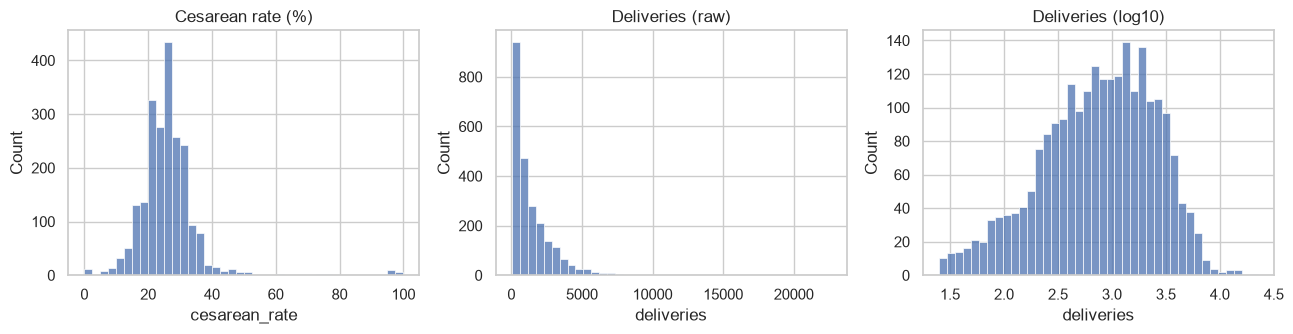

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))

sns.histplot(labelled["cesarean_rate"].dropna(), bins=40, ax=ax[0])
ax[0].set_title("Cesarean rate (%)")

sns.histplot(labelled["deliveries"].dropna(), bins=40, ax=ax[1])
ax[1].set_title("Deliveries (raw)")

sns.histplot(np.log10(labelled["deliveries"].dropna()), bins=40, ax=ax[2])
ax[2].set_title("Deliveries (log10)")

fig.tight_layout()
plt.show()

To make the patterns easier to compare, I group hospitals into quintiles for cesarean rate and delivery volume, then calculate the share of Bottom Performers in each group.

In [26]:
def rate_by_quintile(col):
    q = pd.qcut(labelled[col], 5)
    g = labelled.groupby(q, observed=True)["is_bottom"].agg(["mean", "size"])
    g.index = [f"{max(i.left, 0):.0f}-{i.right:.0f}" for i in g.index]
    return g

ces = rate_by_quintile("cesarean_rate")
vol = rate_by_quintile("deliveries")

print(ces.round(3).to_string())
print()
print(vol.round(3).to_string())

         mean  size
0-20    0.215   475
20-24   0.218   510
24-27   0.237   434
27-30   0.307   365
30-100  0.325   397

             mean  size
25-263      0.260   473
263-592     0.218   472
592-1162    0.208   471
1162-2227   0.256   472
2227-22616  0.311   472


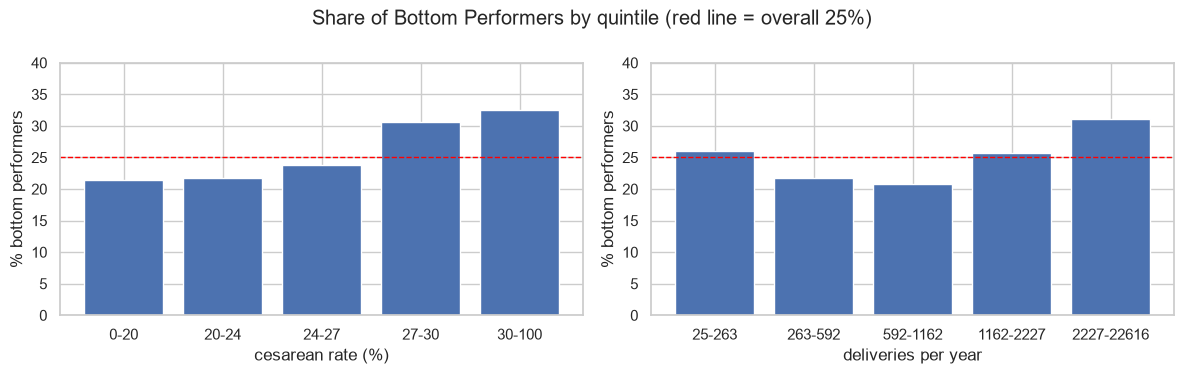

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))

for axis, g, name in [(ax[0], ces, "cesarean rate (%)"), (ax[1], vol, "deliveries per year")]:
    axis.bar(g.index, 100 * g["mean"])
    axis.axhline(100 * labelled["is_bottom"].mean(), color="red", ls="--", lw=1)
    axis.set_ylim(0, 40)
    axis.set_xlabel(name)
    axis.set_ylabel("% bottom performers")

fig.suptitle("Share of Bottom Performers by quintile (red line = overall 25%)")
fig.tight_layout()
plt.show()

I then turn to geography, comparing states with at least 25 scored hospitals so that the groups are not too small.

In [28]:
by_state = (labelled.groupby("State")["is_bottom"].agg(["mean", "size"])
            .query("size >= 25").sort_values("mean"))

print("states with 25+ scored hospitals:", len(by_state))
print("range: %.0f%% to %.0f%%" % (100 * by_state["mean"].min(), 100 * by_state["mean"].max()))
print()
print(pd.concat([by_state.head(5), by_state.tail(5)]).round(3).to_string())

states with 25+ scored hospitals: 34
range: 8% to 51%

        mean  size
State             
KS     0.077    39
OH     0.077    78
WI     0.097    72
MO     0.107    56
UT     0.122    41
NJ     0.386    44
CO     0.408    49
AL     0.421    38
MA     0.459    37
NY     0.510   100


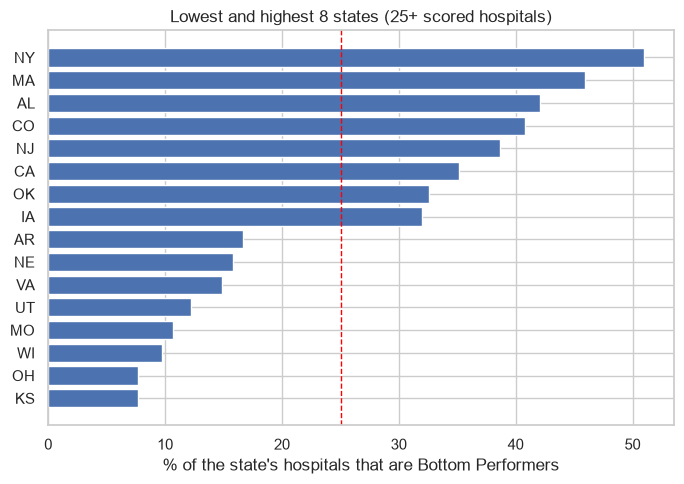

In [29]:
ends = pd.concat([by_state.head(8), by_state.tail(8)])

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(ends.index, 100 * ends["mean"])
ax.axvline(100 * labelled["is_bottom"].mean(), color="red", ls="--", lw=1)
ax.set_xlabel("% of the state's hospitals that are Bottom Performers")
ax.set_title("Lowest and highest 8 states (25+ scored hospitals)")
fig.tight_layout()
plt.show()

Two other characteristics seem worth exploring: the safety attestation and a rough indicator of academic affiliation based on the hospital's name.

In [30]:
labelled["sm7_adopted"] = (labelled["sm7"] == "Yes").astype(int)

name = labelled["Facility Name"].str.upper()
labelled["is_academic"] = name.str.contains(r"UNIV|COLLEGE|SCHOOL OF MED",
                                            regex=True, na=False).astype(int)

for col in ["sm7_adopted", "is_academic"]:
    print(col)
    print(labelled.groupby(col)["is_bottom"].agg(["mean", "size"]).round(3).to_string())
    print()

sm7_adopted
              mean  size
sm7_adopted             
0            0.247   186
1            0.251  2174

is_academic
              mean  size
is_academic             
0            0.243  2268
1            0.446    92



Some cesarean rates stand out, so I take a closer look at the extremes and their sample sizes. I also repeat the comparison after excluding smaller samples to see whether the pattern holds.

In [31]:
print("cesarean rate of exactly 0 :", int((labelled["cesarean_rate"] == 0).sum()))
print("cesarean rate >= 60%       :", int((labelled["cesarean_rate"] >= 60).sum()))
print()
extreme = labelled[(labelled["cesarean_rate"] == 0) | (labelled["cesarean_rate"] >= 60)]
print(extreme[["cesarean_rate", "ntsv_births", "deliveries"]].head(8).to_string())
print()
for floor in [0, 100, 200]:
    sub = labelled[labelled["ntsv_births"].fillna(0) >= floor]
    g = sub.groupby(pd.qcut(sub["cesarean_rate"], 5), observed=True)["is_bottom"].mean()
    print("ntsv >= %-4d n=%4d  lowest quintile %.3f -> highest %.3f"
          % (floor, len(sub), g.iloc[0], g.iloc[-1]))

cesarean rate of exactly 0 : 9
cesarean rate >= 60%       : 24

             cesarean_rate  ntsv_births  deliveries
Facility ID                                        
010099                60.0         40.0       183.0
030117                 0.0         45.0       485.0
050195                99.0        178.0       525.0
150048               100.0         55.0       191.0
180092                 0.0        133.0       405.0
180101                 0.0        110.0       378.0
190116                97.0         63.0       194.0
210008                97.0        341.0      1177.0

ntsv >= 0    n=2360  lowest quintile 0.215 -> highest 0.325
ntsv >= 100  n=1747  lowest quintile 0.194 -> highest 0.319
ntsv >= 200  n=1346  lowest quintile 0.191 -> highest 0.318


## 5. Preparing the model inputs

With the initial exploration complete, I put together the final features. I log-transform delivery volume and pool states with fewer than 25 labelled hospitals into an OTHER category.

In [32]:
model_df = labelled.copy()
model_df["log_deliveries"] = np.log10(model_df["deliveries"])

counts = model_df["State"].value_counts()
big = counts[counts >= 25].index
model_df["state_grp"] = np.where(model_df["State"].isin(big), model_df["State"], "OTHER")

print("states kept:", len(big))
print("hospitals pooled into OTHER:", int((model_df["state_grp"] == "OTHER").sum()))

states kept: 34
hospitals pooled into OTHER: 261


I set aside a stratified test sample, then prepare a pipeline to fill missing numeric values, scale the numeric features and encode the state groups.

In [33]:
NUMERIC = ["cesarean_rate", "log_deliveries"]
BINARY = ["is_academic"]
CATEGORICAL = ["state_grp"]
FEATURES = NUMERIC + BINARY + CATEGORICAL

X = model_df[FEATURES]
y = model_df["is_bottom"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,
                                                    random_state=SEED, stratify=y)

prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC),
    ("bin", "passthrough", BINARY),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), CATEGORICAL),
])

print("train", X_train.shape, "test", X_test.shape)
print("positive rate, train %.3f | test %.3f" % (y_train.mean(), y_test.mean()))
print("columns after encoding:", prep.fit(X_train).transform(X_train).shape[1])

train (1770, 4) test (590, 4)
positive rate, train 0.251 | test 0.251
columns after encoding: 37


## 6. Comparing models

I compare logistic regression and a random forest using cross-validation. A dummy classifier provides a baseline, so I can see whether either model learns more than the majority-class prediction.

In [34]:
models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=8,
                                            class_weight="balanced", random_state=SEED, n_jobs=1),
}

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
for name, est in models.items():
    s = cross_val_score(Pipeline([("prep", prep), ("clf", est)]), X_train, y_train,
                        cv=cv, scoring="roc_auc", n_jobs=1)
    print("%-20s %.4f +/- %.4f" % (name, s.mean(), s.std()))

Dummy                0.5000 +/- 0.0000
Logistic regression  0.6159 +/- 0.0340
Random forest        0.6162 +/- 0.0305


The random forest comes out ahead by just 0.0003 in this comparison. That is a tiny difference, so I repeat cross-validation with five different fold seeds to see how stable it is.

In [35]:
seeds = [0, 1, 7, 21, 42]
repeated = {}

for name, est in models.items():
    vals = [cross_val_score(Pipeline([("prep", prep), ("clf", est)]), X_train, y_train,
                            cv=StratifiedKFold(5, shuffle=True, random_state=s),
                            scoring="roc_auc", n_jobs=1).mean() for s in seeds]
    repeated[name] = vals
    print("%-20s mean %.4f  per seed %s" % (name, np.mean(vals), np.round(vals, 4)))

Dummy                mean 0.5000  per seed [0.5 0.5 0.5 0.5 0.5]
Logistic regression  mean 0.6115  per seed [0.6047 0.6177 0.5992 0.62   0.6159]
Random forest        mean 0.6167  per seed [0.6064 0.6222 0.6114 0.6275 0.6162]


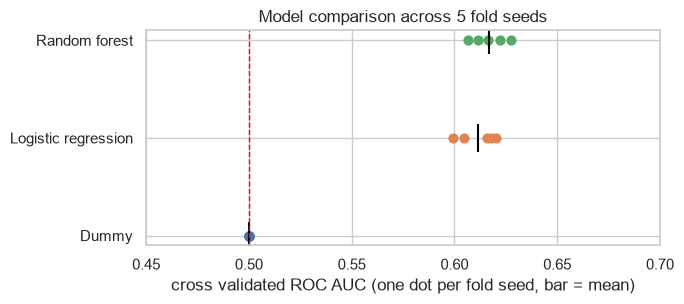

In [36]:
fig, ax = plt.subplots(figsize=(7, 3.2))

for name, vals in repeated.items():
    ax.scatter(vals, [name] * len(vals), s=40)
    ax.scatter([np.mean(vals)], [name], marker="|", s=400, color="black")

ax.axvline(0.5, color="red", ls="--", lw=1)
ax.set_xlim(0.45, 0.70)
ax.set_xlabel("cross validated ROC AUC (one dot per fold seed, bar = mean)")
ax.set_title("Model comparison across 5 fold seeds")
fig.tight_layout()
plt.show()

## 7. Evaluating the chosen model

The two models perform very similarly, so I choose the simpler logistic regression. I fit it on the training data and evaluate its predictions on the held-out test sample.

In [37]:
final = Pipeline([("prep", prep), ("clf", models["Logistic regression"])]).fit(X_train, y_train)

pred = final.predict(X_test)
proba = final.predict_proba(X_test)[:, 1]

print("accuracy  %.3f" % accuracy_score(y_test, pred))
print("precision %.3f" % precision_score(y_test, pred, zero_division=0))
print("recall    %.3f" % recall_score(y_test, pred, zero_division=0))
print("f1        %.3f" % f1_score(y_test, pred, zero_division=0))
print("roc auc   %.3f" % roc_auc_score(y_test, proba))
print()
print(classification_report(y_test, pred, target_names=["not bottom", "bottom"], digits=3))

dummy = Pipeline([("prep", prep), ("clf", models["Dummy"])]).fit(X_train, y_train)
print("dummy for reference: accuracy %.3f, recall %.3f"
      % (accuracy_score(y_test, dummy.predict(X_test)),
         recall_score(y_test, dummy.predict(X_test), zero_division=0)))

accuracy  0.603
precision 0.319
recall    0.514
f1        0.394
roc auc   0.623

              precision    recall  f1-score   support

  not bottom      0.795     0.633     0.705       442
      bottom      0.319     0.514     0.394       148

    accuracy                          0.603       590
   macro avg      0.557     0.573     0.550       590
weighted avg      0.676     0.603     0.627       590

dummy for reference: accuracy 0.749, recall 0.000


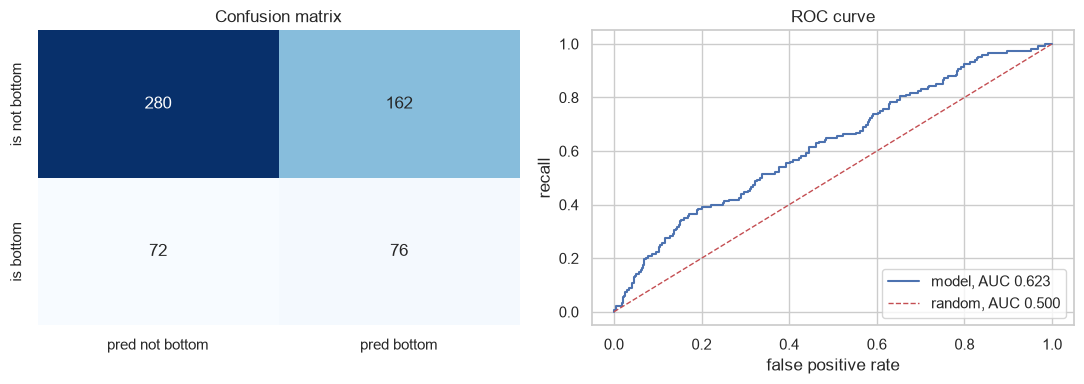

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["pred not bottom", "pred bottom"],
            yticklabels=["is not bottom", "is bottom"])
ax[0].set_title("Confusion matrix")

fpr, tpr, _ = roc_curve(y_test, proba)
ax[1].plot(fpr, tpr, label="model, AUC %.3f" % roc_auc_score(y_test, proba))
ax[1].plot([0, 1], [0, 1], "r--", lw=1, label="random, AUC 0.500")
ax[1].set_xlabel("false positive rate")
ax[1].set_ylabel("recall")
ax[1].set_title("ROC curve")
ax[1].legend(loc="lower right")

fig.tight_layout()
plt.show()

To understand what drives the predictions, I examine permutation importance alongside the fitted coefficients. These describe the model's associations, not causal effects.

In [39]:
perm = permutation_importance(final, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=SEED, n_jobs=1)

print("permutation importance (drop in AUC when shuffled)")
print(pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False).round(4).to_string())

coef = pd.Series(final.named_steps["clf"].coef_[0],
                 index=final.named_steps["prep"].get_feature_names_out())

print("\nnon-state coefficients (log odds):")
print(coef[[c for c in coef.index if not c.startswith("cat__")]].round(3).to_string())

states = coef[[c for c in coef.index if c.startswith("cat__")]].sort_values()
print("\nstate coefficients, 4 lowest and 4 highest:")
print(pd.concat([states.head(4), states.tail(4)]).round(3).to_string())

permutation importance (drop in AUC when shuffled)
state_grp         0.0946
cesarean_rate     0.0152
is_academic       0.0129
log_deliveries   -0.0010

non-state coefficients (log odds):
num__cesarean_rate     0.179
num__log_deliveries   -0.025
bin__is_academic       0.902

state coefficients, 4 lowest and 4 highest:
cat__state_grp_KS   -1.238
cat__state_grp_WI   -1.082
cat__state_grp_OH   -0.897
cat__state_grp_MO   -0.756
cat__state_grp_CA    0.584
cat__state_grp_CO    0.708
cat__state_grp_MA    0.730
cat__state_grp_NY    1.037


Changing the decision threshold changes how many hospitals get flagged. I explore a few cutoffs to show the trade-off between finding more Bottom Performers and raising more false alarms; choosing a threshold would require separate validation.

In [40]:
rows = []
for t in np.arange(0.40, 0.71, 0.05):
    pt = (proba >= t).astype(int)
    rows.append({"threshold": round(t, 2), "flagged": int(pt.sum()),
                 "accuracy": accuracy_score(y_test, pt),
                 "precision": precision_score(y_test, pt, zero_division=0),
                 "recall": recall_score(y_test, pt, zero_division=0),
                 "f1": f1_score(y_test, pt, zero_division=0)})

pd.DataFrame(rows).set_index("threshold").round(3)

,flagged,accuracy,precision,recall,f1
threshold,,,,,
0.40,423,0.442,0.286,0.818,0.424
0.45,336,0.512,0.292,0.662,0.405
0.50,238,0.603,0.319,0.514,0.394
0.55,164,0.671,0.360,0.399,0.378
0.60,119,0.720,0.429,0.345,0.382
0.65,62,0.746,0.484,0.203,0.286
0.70,36,0.742,0.444,0.108,0.174


## 8. Trying a few example hospitals

Finally, I score three hypothetical hospitals to see how different combinations of characteristics translate into model scores and flags.

In [41]:
scenario = pd.DataFrame([
    {"hospital": "A", "cesarean_rate": 31.0, "deliveries": 3000, "is_academic": 1, "State": "NY"},
    {"hospital": "B", "cesarean_rate": 22.0, "deliveries":  900, "is_academic": 0, "State": "OH"},
    {"hospital": "C", "cesarean_rate": 26.0, "deliveries":  250, "is_academic": 0, "State": "TX"},
]).set_index("hospital")

scenario["log_deliveries"] = np.log10(scenario["deliveries"])
scenario["state_grp"] = np.where(scenario["State"].isin(big), scenario["State"], "OTHER")
scenario["score"] = final.predict_proba(scenario[FEATURES])[:, 1]
scenario["flag"] = np.where(scenario["score"] >= 0.50, "yes", "no")

scenario[["State", "cesarean_rate", "deliveries", "is_academic", "score", "flag"]].round(3)

,State,cesarean_rate,deliveries,is_academic,score,flag
hospital,,,,,,
A,NY,31.0,3000,1,0.874,yes
B,OH,22.0,900,0,0.262,no
C,TX,26.0,250,0,0.499,no


## What I take away

State shows the strongest signal in this analysis: the share of Bottom Performers ranges from about 8% in Kansas to 51% in New York. Across cesarean-rate quintiles, that share rises from 21.5% to 32.5%, but this association does not establish that cesareans cause complications. The safety-attestation groups look very similar here, at 25.1% and 24.7%.

The model still has limited predictive power. It identifies roughly half of the Bottom Performers, and only about one in three flags is correct. These results suggest some value for exploratory prioritization, but they do not justify judging a hospital or using the model in practice without further validation.